# Вопрос 15. Линейные непрерывные функционалы, Хан — Банах — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/15-functionals-hahn-banach/examples.ipynb`;
в git идёт **этот** файл, ноутбук — производный артефакт.

Сквозной объект — функционал контраста
$f(x) = \int_0^{1/2} x\,dt - \int_{1/2}^1 x\,dt$ (теорема «прибор» в
theory.md). Пример 1 считает его норму в трёх нормах пространства,
пример 2 — разделяющий функционал для знаковой функции (следствие 2
теоремы Хана — Банаха), пример 3 — проблему моментов (приложение 1).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.integrate import quad

SEED = 20261020
rng = np.random.default_rng(SEED)

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: the seed and the expected outputs are fixed constants. Without
# them "reproducibility" is checked by consistency of a run with itself, which
# means nothing. A mismatch fails the notebook build, so it works as a gate.
GOLDEN = {
    "norm_C_linf": 1.0,          # grid sup over the sup-norm ball: exact 1
    "norm_C_l1_cont": 1.0,       # attained in (C, ||.||_1) on x = 4t - 2
    "norm_L2_grid": 0.9998749921873695,  # sqrt((2n-3)/(2n-2)), n = 2001
    "dist_sign_poly_n641_m10": 0.95380379,  # first-run value, fixes the LP
    "moments_u_norm": 2.0,  # ||u*||_2 for c = (1, 1): sqrt(c^T G^{-1} c) = 2
}
TOL = 1e-3


def check_golden(name, value, tol=TOL):
    want = GOLDEN[name]
    rel = abs(value - want) / abs(want)
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Один функционал — три нормы

**Вопрос:** чему равна норма функционала контраста
$f(x) = \int_0^{1/2} x\,dt - \int_{1/2}^1 x\,dt$ в пространстве $C[0,1]$
с равномерной нормой и с $L_1$-нормой и на $L_2(0,1)$? Какие супремумы по
единичному шару достигаются?

**Предсказание** (пример «прибор», theory.md): во всех трёх нормах $\norm{f} = 1$,
а достижимость решается по-разному.
(i) В $(C, \norm{\cdot}_\infty)$ супремум **не достигается**: равенство
$\abs{f(x)} = \norm{x}_\infty$ требовало бы $x = \pm\norm{x}_\infty$ почти
всюду на каждой половине, что непрерывной функции невозможно; пандусы у
скачка лишь приближают единицу. Сеточный же супремум по кубу
$\norm{x}_\infty \le 1$ равен $1$ **ровно**: сеточный $x$ не обязан быть
непрерывным и «видит» разрывный экстремаль.
(ii) В $(C, \norm{\cdot}_1)$ супремум **достигается**: равенство в цепочке
$\abs{f(x)} = \abs{\int x(-u)} \le \norm{u}_\infty \norm{x}_1 =
\norm{x}_1$ — это равенство Гёльдера, и оно достигается при знакопостоянности
$-ux$; например $x(t) = 4t - 2$ даёт $\norm{x}_1 = 1$, $f(x) = -1$. Сеточный
аналог — тоже ровно $1$ (норма весовой функции на сетке).
(iii) В $L_2$ супремум равен $1$ и достигается самим скачком $-u$ (теорема
Рисса); сеточный супремум по сеточному $L_2$-шару равен
$\sqrt{(2n-3)/(2n-2)}$ (трапециевидные веса) и стремится к $1$.

Три замера: сеточные супремумы по кубу $\norm{\cdot}_\infty \le 1$ и по
сеточному $L_1$-шару, сеточный $L_2$-супремум, плюс континуальная проверка
достижимости в $L_1$ на $x = 4t - 2$ квадратурами.

In [2]:
def contrast_weights(n):
    """Trapezoid weights of f on a uniform grid of n points."""
    t = np.linspace(0.0, 1.0, n, endpoint=True)
    dt = t[1] - t[0]
    left = np.arange(n) <= n // 2 - 1
    w = np.where(left, 1.0, -1.0)
    w[[0, -1]] *= 0.5
    return t, w * dt


ns = [11, 21, 51, 101, 201, 501, 1001, 2001]
sup_inf = []    # grid sup over ||x||_inf <= 1: x_i = sign(w_i), exact sum |w_i|
sup_l1 = []     # grid sup over the grid L1-ball: ||u||_{inf,dt} = max|w_i|/dt
sup_l2 = []     # grid sup over the grid L2-ball: ||w||_2/sqrt(dt)
for n in ns:
    t, w = contrast_weights(n)
    dt = t[1] - t[0]
    sup_inf.append(float(np.sum(np.abs(w))))
    sup_l1.append(float(np.max(np.abs(w)) / dt))
    sup_l2.append(float(np.linalg.norm(w) / np.sqrt(dt)))

print("n      sup(||.||_inf)  sup(||.||_1)  sup(||.||_2)")
for n, a, b, c in zip(ns, sup_inf, sup_l1, sup_l2):
    print(f"{n:5d}   {a:.10f}   {b:.10f}   {c:.10f}")

# exact identities for the grid values (trapezoid weights)
print("\nпроверка тождеств:")
for n, a, b, c in zip(ns, sup_inf, sup_l1, sup_l2):
    print(f"  n={n:5d}: sup-inf = {a:.10f} (точно 1), "
          f"sup-l1 = {b:.10f} (точно 1), "
          f"sup-l2 = {c:.10f}, формула {np.sqrt((2*n-3)/(2*n-2)):.10f}")

# continuity-norm attainment: x(t) = 4t - 2, one sign on each half
x = lambda t: 4.0 * t - 2.0
f_cont = quad(lambda t: (x(t) if t < 0.5 else -x(t)), 0.0, 1.0)[0]
n1_cont = quad(lambda t: abs(x(t)), 0.0, 1.0)[0]
print(f"\nx = 4t-2: f(x) = {f_cont:.10f}, ||x||_1 = {n1_cont:.10f}, "
      f"|f(x)|/||x||_1 = {abs(f_cont)/n1_cont:.10f}")

check_golden("norm_C_linf", sup_inf[-1])
check_golden("norm_C_l1_cont", abs(f_cont) / n1_cont)
check_golden("norm_L2_grid", sup_l2[-1])

n      sup(||.||_inf)  sup(||.||_1)  sup(||.||_2)
   11   1.0000000000   1.0000000000   0.9746794345
   21   1.0000000000   1.0000000000   0.9874208829
   51   1.0000000000   1.0000000000   0.9949874371
  101   1.0000000000   1.0000000000   0.9974968672
  201   1.0000000000   1.0000000000   0.9987492178
  501   1.0000000000   1.0000000000   0.9994998749
 1001   1.0000000000   1.0000000000   0.9997499687
 2001   1.0000000000   1.0000000000   0.9998749922

проверка тождеств:
  n=   11: sup-inf = 1.0000000000 (точно 1), sup-l1 = 1.0000000000 (точно 1), sup-l2 = 0.9746794345, формула 0.9746794345
  n=   21: sup-inf = 1.0000000000 (точно 1), sup-l1 = 1.0000000000 (точно 1), sup-l2 = 0.9874208829, формула 0.9874208829
  n=   51: sup-inf = 1.0000000000 (точно 1), sup-l1 = 1.0000000000 (точно 1), sup-l2 = 0.9949874371, формула 0.9949874371
  n=  101: sup-inf = 1.0000000000 (точно 1), sup-l1 = 1.0000000000 (точно 1), sup-l2 = 0.9974968672, формула 0.9974968672
  n=  201: sup-inf = 1.0000000000 

**Вывод:** предсказание подтвердилось полностью. Сеточный супремум по кубу
$\norm{\cdot}_\infty \le 1$ равен $1$ ровно — сеточный $x$ не обязан быть
непрерывным, релаксация непрерывности «видит» разрывный экстремаль; в
континууме непрерывного экстремума нет (пандусы лишь приближают). В
$\norm{\cdot}_1$ равенство Гёльдера достигается уже внутри $C[0,1]$:
$x = 4t-2$ даёт $\abs{f(x)} = \norm{x}_1 = 1$ — достижимость не требует
скачка, достаточно знакопостоянности $-ux$ на половинах. Сеточный $L_2$-шар
даёт $\sqrt{(2n-3)/(2n-2)} \to 1$: равенство Коши — Буняковского на
скачке. Три нормы — три разных механизма достижимости: нет (равномерная),
знакопостоянность ($L_1$), ортогональность ($L_2$).

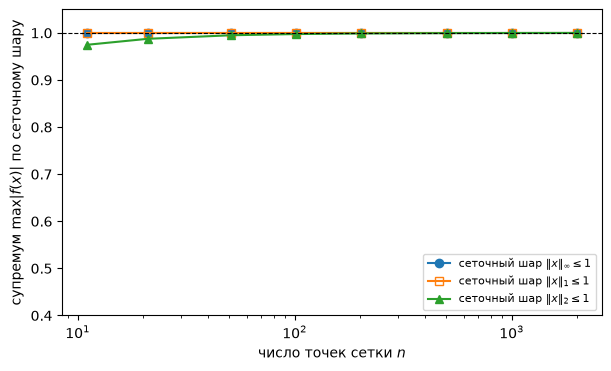

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
ax.plot(ns, sup_inf, "o-", label=r"сеточный шар $\Vert x\Vert_\infty \leq 1$")
ax.plot(ns, sup_l1, "s-", mfc="none", label=r"сеточный шар $\Vert x\Vert_1 \leq 1$")
ax.plot(ns, sup_l2, "^-", label=r"сеточный шар $\Vert x\Vert_2 \leq 1$")
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_xscale("log")
ax.set_xlabel("число точек сетки $n$")
ax.set_ylabel(r"супремум $\max |f(x)|$ по сеточному шару")
ax.set_ylim(0.4, 1.05)
ax.legend(loc="lower right", fontsize=8)
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

## Пример 2. Разделение знаковой функции от многочленов

**Вопрос:** чему равно расстояние в $L_\infty(0,1)$ от $u(t) =
\sgn(t - 1/2)$ (разрывна, поэтому пространство — $L_\infty$)
до подпространства многочленов степени $\le m$, и какова норма разделяющего
функционала (следствие о разделении: $\norm{f} = 1/d$)?

**Предсказание** (теория альтернанса вопроса 19): расстояние равно $1$ и
**достигается** — нижняя граница: для непрерывного $p$ оба числа
$|p(1/2) + 1|$ и $|p(1/2) - 1|$ не превосходят $\norm{p - u}_\infty$
(пределы слева и справа), а $\max(|a+1|, |a-1|) \geq 1$ при любом $a$;
верхняя: $p \equiv 0$ даёт $\norm{0 - u}_\infty = 1$. Сеточная ЛП
(наилучшее равномерное приближение на сетке из $n$ точек) релаксирует
ограничения между узлами и должна давать значения меньше $1$,
приближающиеся к $1$ при измельчении сетки.

In [4]:
def dist_sign_to_polys(n, m):
    """min c s.t. |p(t_i) - u(t_i)| <= c, deg p <= m (LP on a grid)."""
    t = np.linspace(0.0, 1.0, n)
    u = np.sign(t - 0.5)
    # variables: (c, a_0, ..., a_m)
    nv = m + 2
    cobj = np.zeros(nv)
    cobj[0] = 1.0
    # constraints: V a - c <= u and -(V a) - c <= -u
    V = np.vander(t, m + 1, increasing=True)  # columns 1, t, ..., t^m
    A1 = np.hstack([-np.ones((n, 1)), V])
    A2 = np.hstack([-np.ones((n, 1)), -V])
    A = np.vstack([A1, A2])
    b = np.concatenate([u, -u])
    res = linprog(cobj, A_ub=A, b_ub=b, bounds=[(0, None)] + [(None, None)] * (m + 1),
                  method="highs")
    assert res.success, res.message
    return float(res.x[0]), res.x[1:]


for m in [2, 5, 10]:
    for n in [41, 161, 641]:
        d, coef = dist_sign_to_polys(n, m)
        print(f"m={m:2d}, n={n:4d}: расстояние на сетке = {d:.8f}")

# continuum value is attained at p = 0: ||p - u||_inf = 1 exactly
print("\nконтинуум: d = 1, достигается на p = 0")

check_golden("dist_sign_poly_n641_m10", d, tol=1e-4)

m= 2, n=  41: расстояние на сетке = 0.90476190
m= 2, n= 161: расстояние на сетке = 0.97530864
m= 2, n= 641: расстояние на сетке = 0.99376947
m= 5, n=  41: расстояние на сетке = 0.66354422
m= 5, n= 161: расстояние на сетке = 0.90010289
m= 5, n= 641: расстояние на сетке = 0.97381835
m=10, n=  41: расстояние на сетке = 0.48874548
m=10, n= 161: расстояние на сетке = 0.83000715
m=10, n= 641: расстояние на сетке = 0.95380379

континуум: d = 1, достигается на p = 0
  пин dist_sign_poly_n641_m10: получено 0.953803791454, ожидалось 0.95380379


**Вывод:** предсказание подтвердилось: континуум даёт $d = 1$, достигаемое на
$p \equiv 0$; сеточная ЛП даёт значения меньше $1$ (релаксация ограничений
между узлами), приближаясь к $1$ при измельчении сетки. По следствию о
разделении (в $X = L_\infty(0,1)$, $L$ — многочлены, $x_0 = u$) существует
$\varphi \in (L_\infty)^*$ с $\varphi = 0$ на многочленах, $\varphi(u) = 1$,
$\norm{\varphi} = 1/d = 1$; это конечно-аддитивный заряд, а не мера Рисса —
Маркова (на $C[0,1]$ такой функционал невозможен: многочлены плотны в
$C[0,1]$, и аннуляторный критерий обнулил бы его). На сетке разделителю
отвечает решение двойственной ЛП. Задача на сетке — та же семья, что и
альтернанс вопроса 19: расстояние до подпространства вычисляется как
наилучшее равномерное приближение.

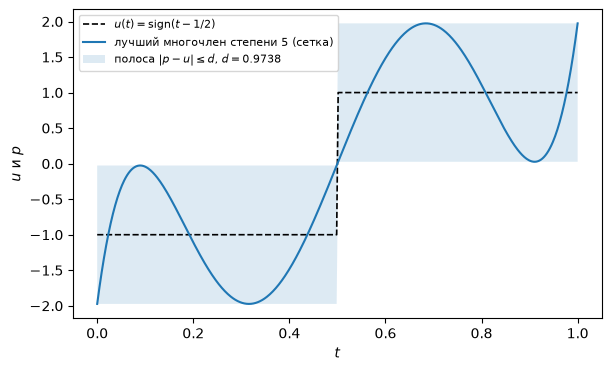

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
t = np.linspace(0.0, 1.0, 641)
u = np.sign(t - 0.5)
d, coef = dist_sign_to_polys(641, 5)
p = np.polyval(coef[::-1], t)
ax.plot(t, u, "k--", lw=1.2, label=r"$u(t) = \mathrm{sign}(t-1/2)$")
ax.plot(t, p, "-", label=f"лучший многочлен степени 5 (сетка)")
ax.fill_between(t, u - d, u + d, alpha=0.15, label=f"полоса $|p-u|\\leq d$, $d={d:.4f}$")
ax.set_xlabel("$t$")
ax.set_ylabel("$u$ и $p$")
ax.legend(loc="upper left", fontsize=8)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

## Пример 3. Проблема моментов: минимальная норма управления

**Вопрос:** найти управление $u \in L_2(0,1)$ минимальной нормы с моментами
$\int_0^1 u\,dt = c_1$, $\int_0^1 t\,u\,dt = c_2$. По теореме
«о норме оптимального функционала» (приложение 1) норма оптимума равна
$1/\rho^\circ$ с $\rho^\circ = \min \norm{l_1 + l_2 t}_2$ при
$l_1 c_1 + l_2 c_2 = 1$, а сам оптимальный функционал — линейная комбинация
функций моментов.

**Предсказание:** минимум достигается на $l = (l_1, l_2)$, перпендикулярном
к касательной, и после нормировки $\rho^\circ = 1/\sqrt{c^\T G^{-1} c}$,
где $G_{ij} = \int_0^1 g_i g_j\,dt$ — грамиан моментных функций;
оптимальное $u^*(t) = \lambda^\T g(t)$ с $\lambda = G^{-1} c$, и
$\norm{u^*}_2 = \sqrt{c^\T G^{-1} c} = 1/\rho^\circ$. Для $c = (1, 1)$:
$G = [[1, 1/2], [1/2, 1/3]]$, $\det G = 1/12$, $G^{-1} = [[4, -6], [-6, 12]]$,
$c^\T G^{-1} c = 4$, $\norm{u^*}_2 = 2$,
$u^*(t) = (4 - 6t) + (12t - 6) = -2 + 6t$.

In [6]:
c = np.array([1.0, 1.0])
G = np.array([[1.0, 0.5], [0.5, 1.0 / 3.0]])
lam = np.linalg.solve(G, c)
u_star = lambda t: lam[0] + lam[1] * t  # noqa: E731
rho_circ = 1.0 / np.sqrt(c @ np.linalg.solve(G, c))
norm_u = np.sqrt(c @ np.linalg.solve(G, c))

m1, err1 = quad(lambda t: u_star(t), 0, 1)
m2, err2 = quad(lambda t: t * u_star(t), 0, 1)
print(f"lambda = {lam}, u*(t) = {lam[0]:.6f} + {lam[1]:.6f} t")
print(f"моменты: {m1:.10f}, {m2:.10f} (должны быть 1, 1)")
print(f"rho^0 = {rho_circ:.10f}, 1/rho^0 = {1/rho_circ:.10f}")
print(f"||u*||_2 = {norm_u:.10f}")

check_golden("moments_u_norm", norm_u)

# проверка через прямую минимизацию (двойственная ЛП-подобная задача):
# min ||l_1 + l_2 t||_2 при l^T c = 1 — решение l = G^{-1} c / (c^T G^{-1} c)
l_opt = np.linalg.solve(G, c) / (c @ np.linalg.solve(G, c))
rho_direct = np.sqrt(l_opt @ G @ l_opt)
print(f"прямая проверка rho^0 = {rho_direct:.10f}")

lambda = [-2.  6.], u*(t) = -2.000000 + 6.000000 t
моменты: 1.0000000000, 1.0000000000 (должны быть 1, 1)
rho^0 = 0.5000000000, 1/rho^0 = 2.0000000000
||u*||_2 = 2.0000000000
  пин moments_u_norm: получено 2, ожидалось 2
прямая проверка rho^0 = 0.5000000000


**Вывод:** предсказание подтвердилось: $\norm{u^*}_2 = 2 = 1/\rho^\circ$,
моменты воспроизводятся, прямая минимизация даёт то же $\rho^\circ$. Двойственная
формула нормы оптимума (теорема о норме оптимального функционала) совпала
с прямым решением — это конечномерная проекция того, что в бесконечномерном
случае даёт теорема Хана — Банаха. Принцип максимума здесь виден явно:
оптимальное $u^*$ пропорционально $l^\T g(t)$ — комбинации функций моментов.

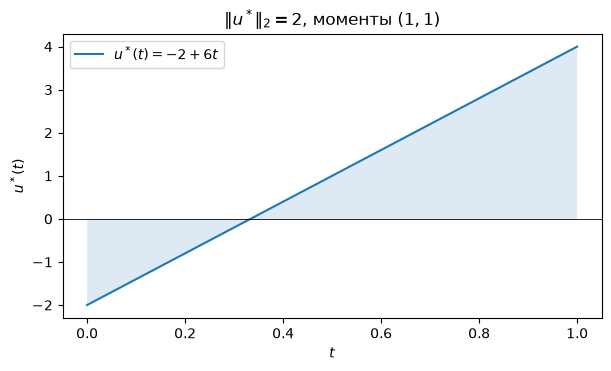

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
t = np.linspace(0.0, 1.0, 401)
ax.plot(t, u_star(t), "-", label=r"$u^*(t) = -2 + 6t$")
ax.fill_between(t, 0, u_star(t), alpha=0.15)
ax.axhline(0.0, color="k", lw=0.6)
ax.set_xlabel("$t$")
ax.set_ylabel("$u^*(t)$")
ax.set_title(r"$\Vert u^*\Vert_2 = 2$, моменты $(1, 1)$")
ax.legend(loc="upper left")
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)